# Chương 2: Mô hình hóa tín hiệu và nguồn nhiễu
## Import thư viện và cấu hình chung

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Reproducibility
SEED = 42

# Sampling configuration
FS = 30.0
TS = 1 / FS
TE = 0.004
N = 1800

# Ground truth parameters
X0 = 100.0
SIGMA_S = 0.02
RHO = 0.9
SIGMA_F = 4.0
STEP_DN = 20.0
STEP_INDEX = N // 2

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "figure.dpi": 120,
    "axes.grid": True,
    "font.size": 11
})

print("Sampling frequency:", FS, "Hz")
print("Number of samples:", N)
print("Recording duration:", N / FS, "s")

Sampling frequency: 30.0 Hz
Number of samples: 1800
Recording duration: 60.0 s


## Xây dựng hàm sinh độ sáng thực

In [5]:
def generate_ground_truth(
    rng, n_samples=N, step=0.0, static=False
):
    # Slow component: Random Walk
    ws = rng.normal(
        0, SIGMA_S, n_samples - 1
    )
    xs = np.r_[X0, X0 + np.cumsum(ws)]

    # Fast component: AR(1)
    xf = np.empty(n_samples)

    # Initialize from stationary distribution
    xf[0] = rng.normal(0, SIGMA_F)

    sigma_wf = SIGMA_F * np.sqrt(1 - RHO**2)

    wf = rng.normal(
        0, sigma_wf, n_samples - 1
    )

    for n in range(1, n_samples):
        xf[n] = RHO * xf[n - 1] + wf[n - 1]

    # Static illumination condition
    if static:
        xs[:] = X0
        xf[:] = 0.0

    # Sudden illumination change
    xs[n_samples // 2:] += step

    # Ground truth
    x = xs + xf

    return xs, xf, x

## Hiển thị các thành phần của ground truth

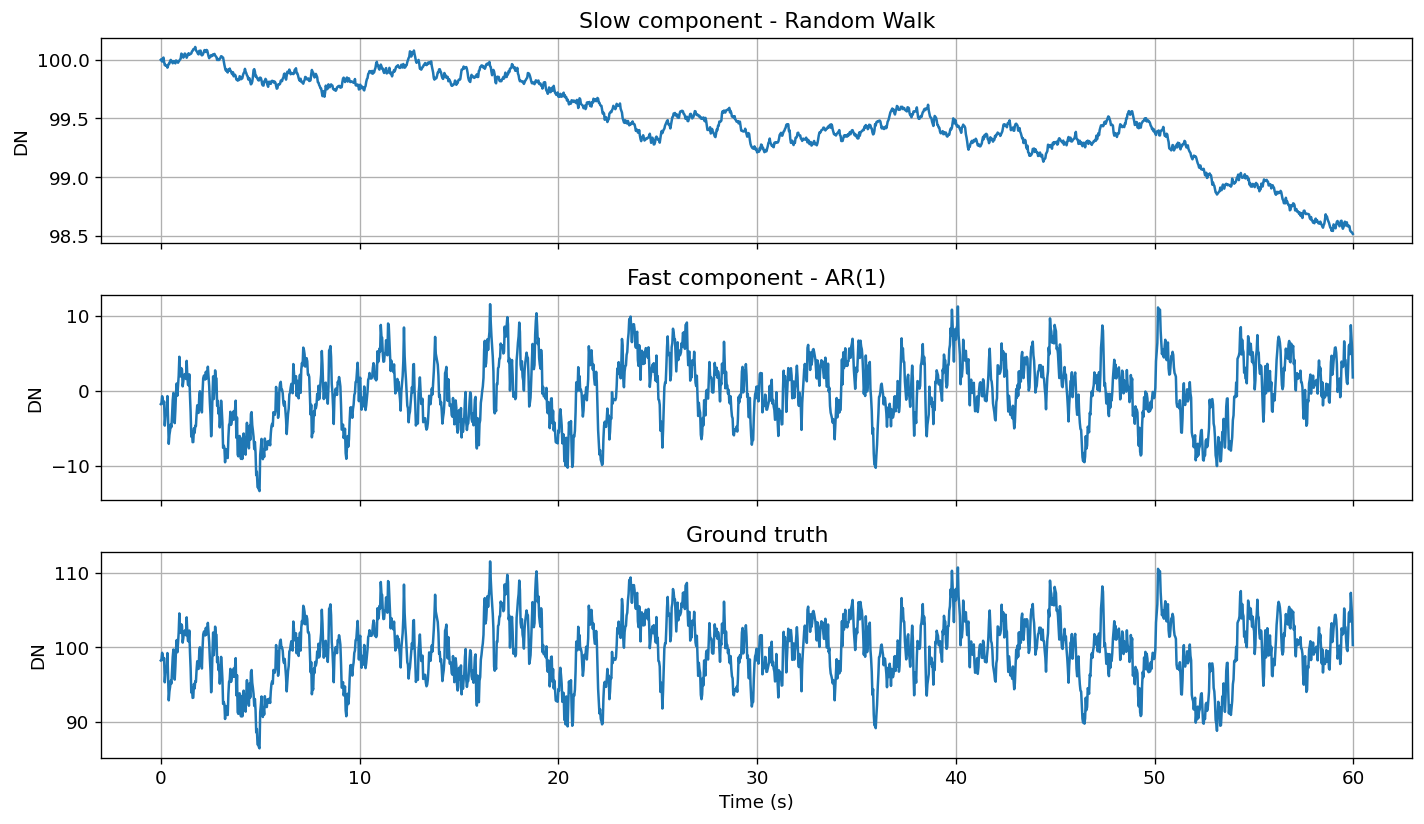

Mean of x: 99.639 DN
Std of xf: 4.240 DN


In [6]:
rng = np.random.default_rng(SEED)

t = np.arange(N) / FS
xs, xf, x = generate_ground_truth(rng)

fig, ax = plt.subplots(
    3, 1, figsize=(12, 7), sharex=True
)

ax[0].plot(t, xs)
ax[0].set_title("Slow component - Random Walk")
ax[0].set_ylabel("DN")

ax[1].plot(t, xf)
ax[1].set_title("Fast component - AR(1)")
ax[1].set_ylabel("DN")

ax[2].plot(t, x)
ax[2].set_title("Ground truth")
ax[2].set_ylabel("DN")
ax[2].set_xlabel("Time (s)")

fig.tight_layout()
fig.savefig(
    FIG_DIR / "ground_truth.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print(f"Mean of x: {np.mean(x):.3f} DN")
print(f"Std of xf: {np.std(xf):.3f} DN")

## Cấu hình cảm biến và kiểm chứng shot noise

In [7]:
# Camera reference parameters
BIT_DEPTH = 12
DN_MAX = 2**BIT_DEPTH - 1
K = 0.353
DARK_NOISE_E = 3.664

# Equivalent dark/read noise before quantization
SIGMA_R = K * DARK_NOISE_E

def generate_shot_noise(rng, u):
    u = np.asarray(u, dtype=float)

    if np.any(u < 0):
        raise ValueError("Negative optical signal")

    lambda_e = u / K
    ne = rng.poisson(lambda_e)

    # Shot noise in DN
    v_shot = K * ne - u

    return ne, v_shot


rng = np.random.default_rng(123)

for level in [20, 100, 200]:
    u_test = np.full(100_000, level, dtype=float)
    _, noise = generate_shot_noise(rng, u_test)

    print(
        f"Signal = {level:3d} DN | "
        f"Mean = {np.mean(noise):7.4f} | "
        f"Variance = {np.var(noise):7.3f} | "
        f"Theory = {K * level:7.3f}"
    )

Signal =  20 DN | Mean = -0.0060 | Variance =   7.031 | Theory =   7.060
Signal = 100 DN | Mean = -0.0036 | Variance =  35.049 | Theory =  35.300
Signal = 200 DN | Mean =  0.0035 | Variance =  70.262 | Theory =  70.600


## Hàm lượng tử hóa và giới hạn miền giá trị

In [8]:
def quantize_adc(signal):
    rounded = np.rint(signal)
    quantized = np.clip(rounded, 0, DN_MAX)

    clipping_count = np.count_nonzero(
        rounded != quantized
    )

    return quantized, clipping_count

## Mô hình black level

In [9]:
B0 = 16.0
SIGMA_D = 0.05

# Optical Black equivalent read noise
SIGMA_OB = SIGMA_R

def generate_black_level(rng, n_samples=N):
    wd = rng.normal(
        0, SIGMA_D, n_samples - 1
    )

    drift = np.r_[0.0, np.cumsum(wd)]
    b = B0 + drift

    return b

## Hàm sinh thành phần Flicker

In [10]:
FM = 50.0
MOD_DEPTH = 0.25

def generate_flicker(
    rng, x,
    modulation=MOD_DEPTH,
    grid_drift=0.0
):
    n_samples = len(x)
    t = np.arange(n_samples) / FS

    # Grid frequency
    fm = np.linspace(
        FM,
        FM + grid_drift,
        n_samples
    )

    # Physical flicker frequency
    ff = 2 * fm

    # Exposure attenuation
    he = np.sinc(ff * TE)

    # Initial random phase
    phi0 = rng.uniform(0, 2 * np.pi)

    # Phase accumulation:
    # supports time-varying frequency
    phase_increment = (
        2 * np.pi
        * (ff[1:] + ff[:-1])
        / (2 * FS)
    )

    phase = phi0 + np.r_[
        0.0,
        np.cumsum(phase_increment)
    ]

    # Multiplicative flicker
    flicker = (
        modulation * he * x * np.cos(phase)
    )

    return flicker, ff

## Kiểm chứng ảnh hưởng của phơi sáng và aliasing

Flicker frequency: 100.00 Hz
Alias frequency: 10.00 Hz
Exposure response: 0.756827
Effective modulation: 0.189207


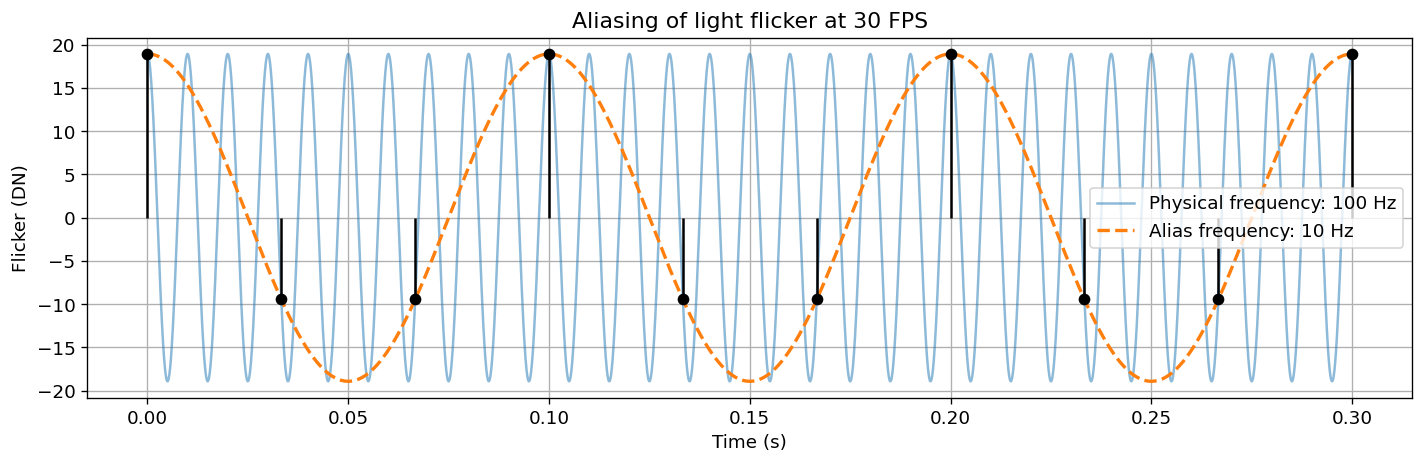

In [11]:
f_flicker = 2 * FM

he = np.sinc(f_flicker * TE)

f_alias = abs(
    (f_flicker + FS / 2) % FS - FS / 2
)

print(f"Flicker frequency: {f_flicker:.2f} Hz")
print(f"Alias frequency: {f_alias:.2f} Hz")
print(f"Exposure response: {he:.6f}")
print(f"Effective modulation: {MOD_DEPTH * he:.6f}")

# Continuous optical modulation after exposure
t_cont = np.linspace(0, 0.3, 5000)

signal_cont = (
    100 * MOD_DEPTH * he
    * np.cos(2 * np.pi * f_flicker * t_cont)
)

# Samples observed by the camera
t_sample = np.arange(10) / FS

signal_sample = (
    100 * MOD_DEPTH * he
    * np.cos(2 * np.pi * f_flicker * t_sample)
)

# Equivalent aliased signal
signal_alias = (
    100 * MOD_DEPTH * he
    * np.cos(2 * np.pi * f_alias * t_cont)
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    t_cont, signal_cont,
    label="Physical frequency: 100 Hz",
    alpha=0.5
)

ax.plot(
    t_cont, signal_alias,
    "--", linewidth=2,
    label="Alias frequency: 10 Hz"
)

ax.stem(
    t_sample, signal_sample,
    linefmt="k-",
    markerfmt="ko",
    basefmt=" "
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Flicker (DN)")
ax.set_title("Aliasing of light flicker at 30 FPS")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "flicker_aliasing.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

Hàm sinh dữ liệu tổng hợp

In [12]:
def simulate(seed=SEED, scenario="S0", n_samples=N):

    valid_scenarios = ["C0", "S0", "S1", "S2"]

    if scenario not in valid_scenarios:
        raise ValueError("Unknown scenario")

    rng = np.random.default_rng(seed)
    t = np.arange(n_samples) / FS

    # 1. Scenario configuration
    static = scenario == "C0"

    step = (
        STEP_DN if scenario == "S1" else 0.0
    )

    modulation = (
        0.0 if scenario == "C0" else MOD_DEPTH
    )

    grid_drift = (
        0.3 if scenario == "S2" else 0.0
    )

    # 2. Ground truth
    xs, xf, x = generate_ground_truth(
        rng,
        n_samples=n_samples,
        step=step,
        static=static
    )

    # 3. Flicker
    flicker, ff = generate_flicker(
        rng,
        x,
        modulation=modulation,
        grid_drift=grid_drift
    )

    # Optical signal before sensor noise
    u = x + flicker

    # 4. Black level offset and drift
    b = generate_black_level(
        rng, n_samples
    )

    # 5. Photon shot noise
    ne, v_shot = generate_shot_noise(rng, u)

    # 6. Read noise
    v_read = rng.normal(
        0, SIGMA_R, n_samples
    )

    v_ob = rng.normal(
        0, SIGMA_OB, n_samples
    )

    # 7. Analog-equivalent measurements
    a1 = K * ne + b + v_read
    a2 = b + v_ob

    # 8. Quantization and clipping
    z1, clip1 = quantize_adc(a1)
    z2, clip2 = quantize_adc(a2)

    # 9. Return all components
    return {
        "seed": seed,
        "scenario": scenario,
        "t": t,
        "xs": xs,
        "xf": xf,
        "x": x,
        "s": flicker,
        "u": u,
        "b": b,
        "ff": ff,
        "ne": ne,
        "vshot": v_shot,
        "vr": v_read,
        "vob": v_ob,
        "a1": a1,
        "a2": a2,
        "vq1": np.rint(a1) - a1,
        "vq2": np.rint(a2) - a2,
        "z1": z1,
        "z2": z2,
        "y": z1 - z2,
        "clip1": clip1,
        "clip2": clip2
    }

## Hiển thị dữ liệu mô phỏng

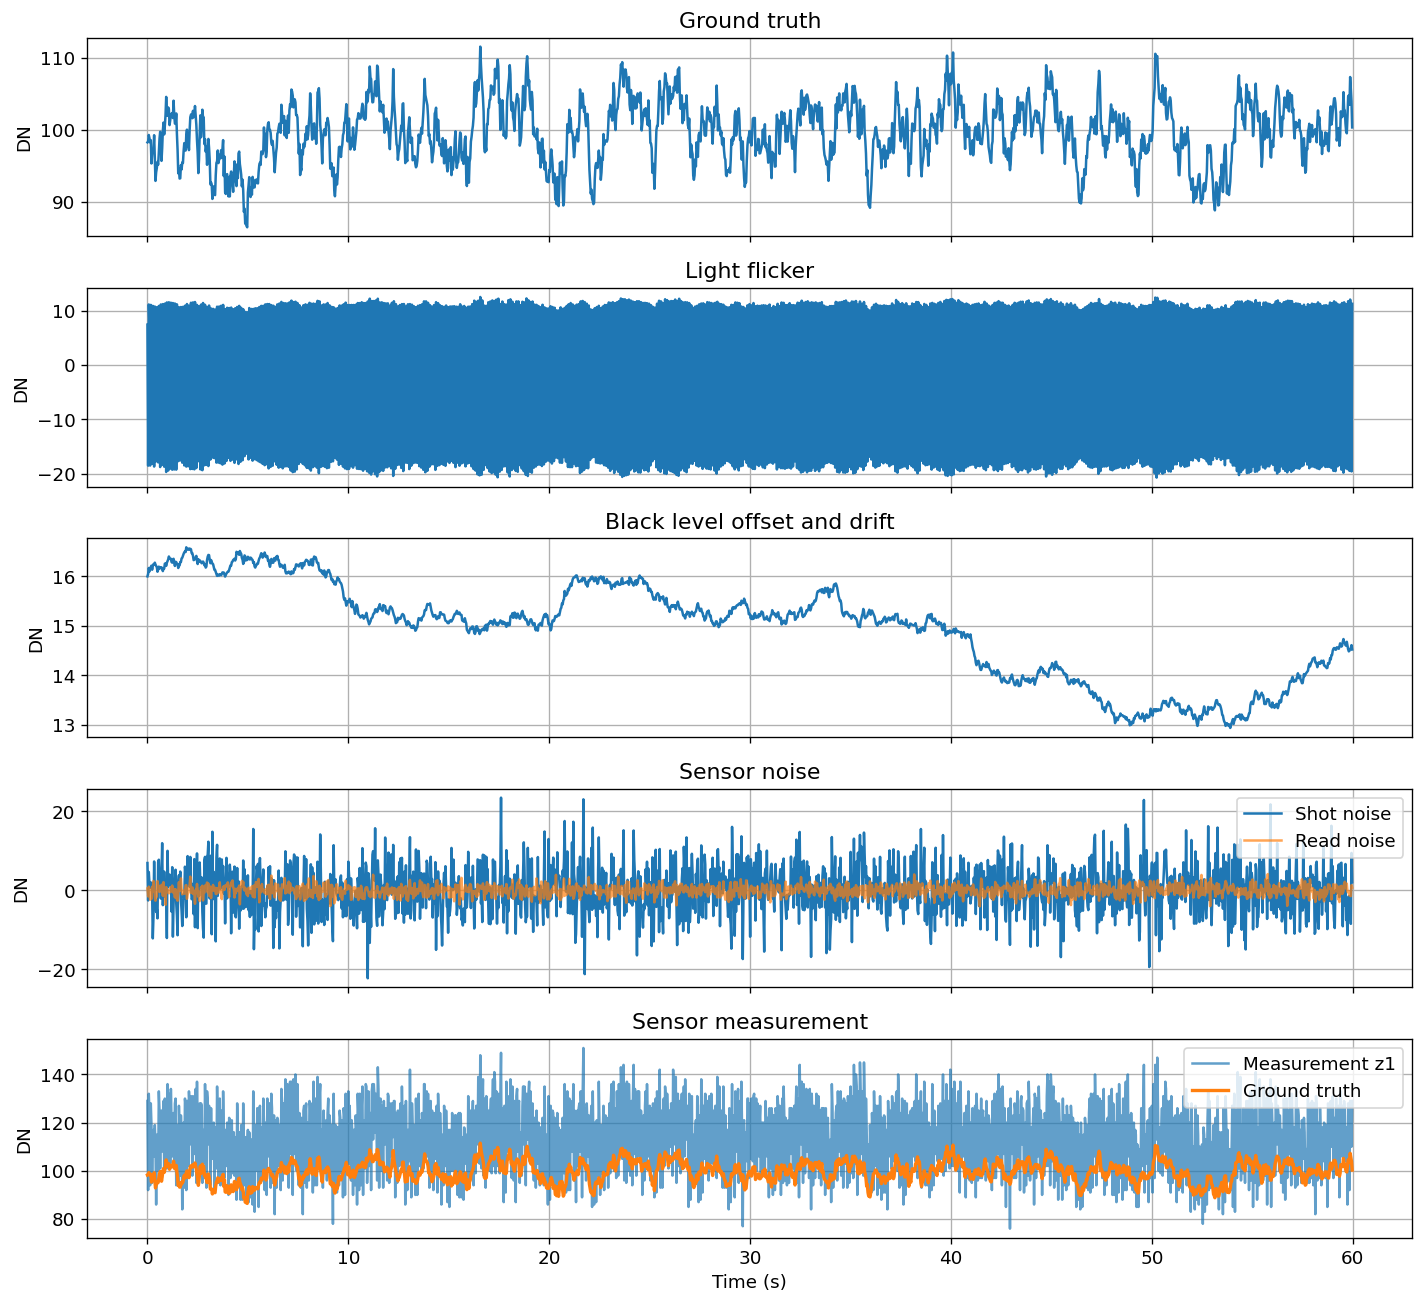

In [13]:
data = simulate(seed=SEED, scenario="S0")

t = data["t"]

fig, ax = plt.subplots(
    5, 1,
    figsize=(12, 11),
    sharex=True
)

ax[0].plot(t, data["x"])
ax[0].set_title("Ground truth")
ax[0].set_ylabel("DN")

ax[1].plot(t, data["s"])
ax[1].set_title("Light flicker")
ax[1].set_ylabel("DN")

ax[2].plot(t, data["b"])
ax[2].set_title("Black level offset and drift")
ax[2].set_ylabel("DN")

ax[3].plot(t, data["vshot"], label="Shot noise")
ax[3].plot(
    t, data["vr"],
    alpha=0.7,
    label="Read noise"
)
ax[3].set_title("Sensor noise")
ax[3].set_ylabel("DN")
ax[3].legend()

ax[4].plot(
    t, data["z1"],
    label="Measurement z1",
    alpha=0.7
)
ax[4].plot(
    t, data["x"],
    label="Ground truth",
    linewidth=2
)
ax[4].set_title("Sensor measurement")
ax[4].set_ylabel("DN")
ax[4].set_xlabel("Time (s)")
ax[4].legend()

fig.tight_layout()

fig.savefig(
    FIG_DIR / "simulation_components.png",
    dpi=300, bbox_inches="tight"
)

plt.show()

## Kiểm tra dữ liệu tại cả 4 kịch bản

In [14]:
for scenario in ["C0", "S0", "S1", "S2"]:

    data = simulate(
        seed=SEED,
        scenario=scenario
    )

    x = data["x"]
    y = data["y"]

    rmse_raw = np.sqrt(
        np.mean((y - x)**2)
    )

    print(f"\nScenario: {scenario}")
    print(f"Mean x: {np.mean(x):.3f} DN")
    print(f"Std AR(1): {np.std(data['xf']):.3f} DN")
    print(f"Std flicker: {np.std(data['s']):.3f} DN")
    print(f"Std shot: {np.std(data['vshot']):.3f} DN")
    print(f"Raw RMSE: {rmse_raw:.3f} DN")

    print(
        f"Clipped samples: "
        f"z1={data['clip1']}, "
        f"z2={data['clip2']}"
    )

    assert len(data["z1"]) == N
    assert len(data["z2"]) == N
    assert np.all(data["u"] >= 0)
    assert np.all(np.isfinite(data["z1"]))
    assert np.all(np.isfinite(data["z2"]))


Scenario: C0
Mean x: 100.000 DN
Std AR(1): 0.000 DN
Std flicker: 0.000 DN
Std shot: 6.112 DN
Raw RMSE: 6.375 DN
Clipped samples: z1=0, z2=0

Scenario: S0
Mean x: 99.639 DN
Std AR(1): 4.240 DN
Std flicker: 13.344 DN
Std shot: 6.102 DN
Raw RMSE: 14.531 DN
Clipped samples: z1=0, z2=0

Scenario: S1
Mean x: 109.639 DN
Std AR(1): 4.240 DN
Std flicker: 14.744 DN
Std shot: 6.389 DN
Raw RMSE: 16.004 DN
Clipped samples: z1=0, z2=0

Scenario: S2
Mean x: 99.639 DN
Std AR(1): 4.240 DN
Std flicker: 13.321 DN
Std shot: 6.074 DN
Raw RMSE: 14.619 DN
Clipped samples: z1=0, z2=0


## Lưu dữ liệu mô phỏng

In [15]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

for scenario in ["C0", "S0", "S1", "S2"]:

    data = simulate(
        seed=SEED,
        scenario=scenario
    )

    np.savez_compressed(
        DATA_DIR / f"{scenario}.npz",
        **data
    )

print("Simulation datasets saved.")

Simulation datasets saved.
